In [1]:
import pandas as pd
import yfinance as yf
import numpy as np  
import matplotlib.pyplot as plt
from scipy.stats import norm
import datetime as dt

In [2]:
years = 15
end_date = dt.datetime.now()
start_date = end_date - dt.timedelta(days=years*365)

In [3]:
tickers = ['SPY', 'GLD', 'QQQ', 'VTI', 'BND']

In [4]:
adj_close_df = pd.DataFrame()

for ticker in tickers:
    data =yf.download(ticker, start = start_date, end = end_date, auto_adjust=False)
    adj_close_df[ticker] =  data['Adj Close']



[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [5]:
print(adj_close_df.head())

                  SPY         GLD        QQQ        VTI        BND
Date                                                              
2010-07-21  81.510681  115.849998  39.081692  41.681282  53.168121
2010-07-22  83.330154  116.860001  40.070988  42.607025  53.109604
2010-07-23  84.053383  116.089996  40.324860  43.043121  53.018524
2010-07-26  84.928848  115.519997  40.657562  43.571018  53.044525
2010-07-27  84.921265  113.510002  40.640030  43.517464  53.018524


In [6]:
#Calculating log returns and droping NaN values

log_returns =np.log(adj_close_df / adj_close_df.shift(1)).dropna()

In [7]:
#calculating expected returns. I am assuming that the future  #expected returns are the same as the historical mean returns.
#This is a simplification and may not hold true in practice, but it serves as a place holder for this project. I should research the expected returns or pay an equity researrcher for this info.

def expected_returns(weights, log_returns):
    return np.sum(log_returns.mean()*weights)


In [8]:
#portfolio standard deviation
def portfolio_std(weights, cov_matrix):
    variance = weights.T @ cov_matrix @ weights
    return np.sqrt(variance)

In [9]:
cov_matrix = log_returns.cov()

In [10]:
portfolio_value = 1000000  
weights =   np.array([1/len(tickers)]*len(tickers))
print(weights)
portfolio_expected_return = expected_returns(weights, log_returns)
portfolio_std_dev = portfolio_std(weights, cov_matrix)


[0.2 0.2 0.2 0.2 0.2]


In [11]:
#creating a function to create random Z scores in a normal distribution
def random_z_score():
    return np.random.normal(0,1)


In [12]:
#function to create scenario gain-loss
days = 20
def scenario_gain_loss(portfolio_value, portfolio_std_dev, z_score, days):
    return portfolio_value *( portfolio_expected_return * days + portfolio_std_dev * z_score * np.sqrt(days))

In [13]:
#running simulations
simulations = 10000
scenario_returns = []

for i in range(simulations):
    z_score =  random_z_score()
    scenario_returns.append(scenario_gain_loss(portfolio_value, portfolio_std_dev, z_score, days))



In [14]:
#Specifying the confidence level and calculating the Value at Risk (VaR)
confidence_interval = 0.95
VaR= -np.percentile(scenario_returns, 100*(1-confidence_interval))

print(VaR)

45188.26583835127


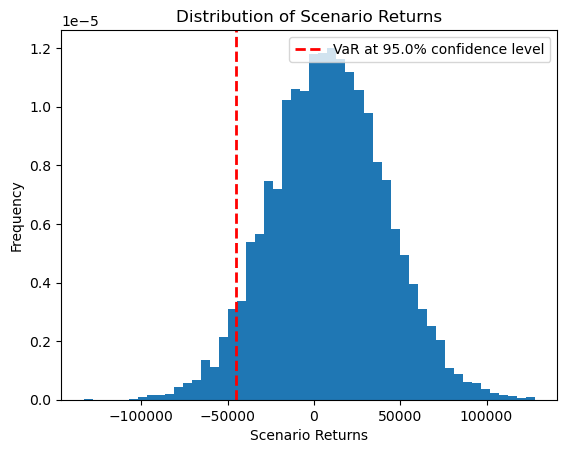

In [15]:
plt.clf()
plt.hist(scenario_returns, bins=50, density=True)
plt.xlabel('Scenario Returns')
plt.ylabel('Frequency')
plt.title('Distribution of Scenario Returns')
plt.axvline(-VaR, color='red', linestyle='dashed', linewidth=2, label=f'VaR at {confidence_interval*100}% confidence level')
plt.legend()
plt.show()